In [131]:
# importing the libraries
get_ipython().system('pip install kagglehub')


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [132]:
# importing the libraries
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns

In [133]:
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

#Vamos utilizar um dataset para análise da possibilidade da profissão ser automatizada na área de programação
## A atividade consiste em explicar o porquê de termos determinadas previsões
### Você pode importar outro modelo o sklearn como XBOOST, SVM para poder comparar quantitativamente a eficiência, mas o objetivo é realizar a interpretação dos resultados com LIME e SHAP

In [134]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("khushikyad001/ai-impact-on-jobs-2030")

print("Path to dataset files:", path)

Path to dataset files: /Users/jwcunha/.cache/kagglehub/datasets/khushikyad001/ai-impact-on-jobs-2030/versions/1


In [135]:
import os      
df = pd.read_csv(os.path.join(path, "AI_Impact_on_Jobs_2030.csv"))

In [136]:
df.head()

,Job_Title,Average_Salary,Years_Experience,Education_Level,AI_Exposure_Index,Tech_Growth_Factor,Automation_Probability_2030,Risk_Category,Skill_1,Skill_2,Skill_3,Skill_4,Skill_5,Skill_6,Skill_7,Skill_8,Skill_9,Skill_10
0,Security Guard,45795,28,Master's,0.18,1.28,0.85,High,0.45,0.10,0.46,0.33,0.14,0.65,0.06,0.72,0.94,0.00
1,Research Scientist,133355,20,PhD,0.62,1.11,0.05,Low,0.02,0.52,0.40,0.05,0.97,0.23,0.09,0.62,0.38,0.98
2,Construction Worker,146216,2,High School,0.86,1.18,0.81,High,0.01,0.94,0.56,0.39,0.02,0.23,0.24,0.68,0.61,0.83
3,Software Engineer,136530,13,PhD,0.39,0.68,0.60,Medium,0.43,0.21,0.57,0.03,0.84,0.45,0.40,0.93,0.73,0.33
4,Financial Analyst,70397,22,High School,0.52,1.46,0.64,Medium,0.75,0.54,0.59,0.97,0.61,0.28,0.30,0.17,0.02,0.42


In [137]:
df.duplicated().sum()

np.int64(0)

In [138]:
from sklearn.preprocessing import  OrdinalEncoder
category=[ 'High School', "Bachelor's","Master's", 'PhD']
ordinal=OrdinalEncoder(categories=[category])
df['Education_Level']=ordinal.fit_transform(df[['Education_Level']])

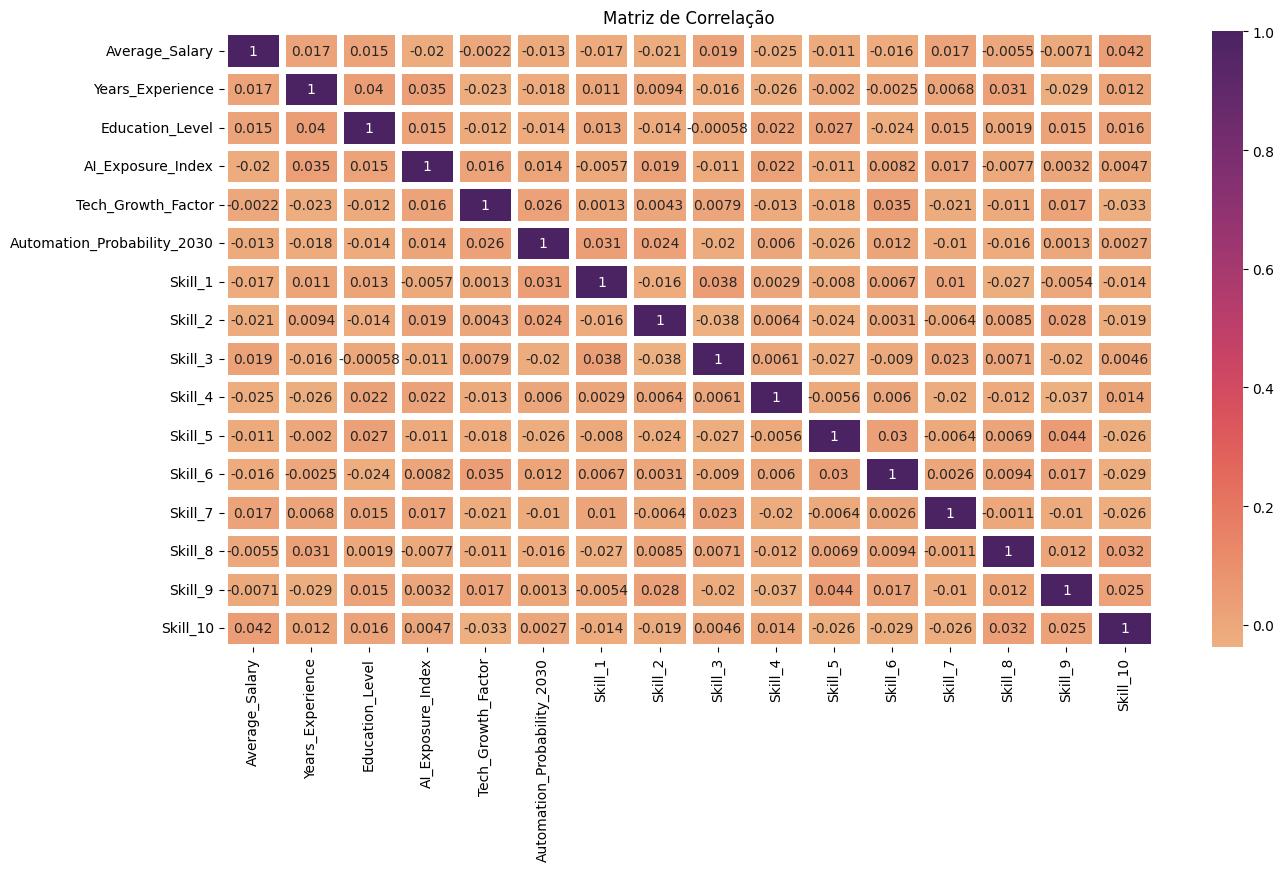

In [139]:
plt.figure(figsize=(15, 8))
sns.heatmap(df.corr(numeric_only=True),annot=True,linewidth=5,cmap='flare')
plt.title('Matriz de Correlação')
plt.show()

#Treinar o modelo
### Treine o modelo com o objetivo de quão está arriscado a carreira da pessoa com determinadas características (features)

#Separe os dados de treinamento

In [140]:
df.head()

,Job_Title,Average_Salary,Years_Experience,Education_Level,AI_Exposure_Index,Tech_Growth_Factor,Automation_Probability_2030,Risk_Category,Skill_1,Skill_2,Skill_3,Skill_4,Skill_5,Skill_6,Skill_7,Skill_8,Skill_9,Skill_10
0,Security Guard,45795,28,2.0,0.18,1.28,0.85,High,0.45,0.10,0.46,0.33,0.14,0.65,0.06,0.72,0.94,0.00
1,Research Scientist,133355,20,3.0,0.62,1.11,0.05,Low,0.02,0.52,0.40,0.05,0.97,0.23,0.09,0.62,0.38,0.98
2,Construction Worker,146216,2,0.0,0.86,1.18,0.81,High,0.01,0.94,0.56,0.39,0.02,0.23,0.24,0.68,0.61,0.83
3,Software Engineer,136530,13,3.0,0.39,0.68,0.60,Medium,0.43,0.21,0.57,0.03,0.84,0.45,0.40,0.93,0.73,0.33
4,Financial Analyst,70397,22,0.0,0.52,1.46,0.64,Medium,0.75,0.54,0.59,0.97,0.61,0.28,0.30,0.17,0.02,0.42


In [141]:
##  Vazamento do alvo
# Risk_Category é derivada direto de Automation_Probability_2030: 
# Low fica em 0.05–0.30, Medium em 0.31–0.70 e High em 0.71–0.95. 
# Ela entra como feature. 
# O RF só reconstrói o alvo, e o SHAP e o LIME vão mostrar essa variável dominante sem valor explicativo. 
# Remova Risk_Category das features (x, célula 13). Usada como alvo, ela viraria um problema de classificação. 

In [142]:
x = df.drop(['Automation_Probability_2030', 'Risk_Category'], axis=1)
y = df['Automation_Probability_2030']

In [143]:
x.head()

,Job_Title,Average_Salary,Years_Experience,Education_Level,AI_Exposure_Index,Tech_Growth_Factor,Skill_1,Skill_2,Skill_3,Skill_4,Skill_5,Skill_6,Skill_7,Skill_8,Skill_9,Skill_10
0,Security Guard,45795,28,2.0,0.18,1.28,0.45,0.10,0.46,0.33,0.14,0.65,0.06,0.72,0.94,0.00
1,Research Scientist,133355,20,3.0,0.62,1.11,0.02,0.52,0.40,0.05,0.97,0.23,0.09,0.62,0.38,0.98
2,Construction Worker,146216,2,0.0,0.86,1.18,0.01,0.94,0.56,0.39,0.02,0.23,0.24,0.68,0.61,0.83
3,Software Engineer,136530,13,3.0,0.39,0.68,0.43,0.21,0.57,0.03,0.84,0.45,0.40,0.93,0.73,0.33
4,Financial Analyst,70397,22,0.0,0.52,1.46,0.75,0.54,0.59,0.97,0.61,0.28,0.30,0.17,0.02,0.42


In [144]:
y.head()

0    0.85
1    0.05
2    0.81
3    0.60
4    0.64
Name: Automation_Probability_2030, dtype: float64

In [145]:
x = pd.get_dummies(x, columns=['Job_Title'], dtype=int)

In [146]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.30, random_state=101)

In [147]:
rf = RandomForestRegressor(random_state=101)

In [148]:
rf.fit(X_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [149]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
pred = rf.predict(X_test)
print('R2:', r2_score(y_test, pred))
print('RMSE:', mean_squared_error(y_test, pred) ** 0.5)
print('MAE:', mean_absolute_error(y_test, pred))

R2: 0.8494446139729452
RMSE: 0.09829151890620519
MAE: 0.08186177777777778


## Instale SHAP E LIME



In [150]:
get_ipython().system('pip install shap')
get_ipython().system('pip install lime')


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [151]:
import shap

# Exemplo com 500 instâncias para teste
X_train_sample = X_train.sample(500, random_state=42)

explainer = shap.TreeExplainer(rf, X_train_sample)


X_test_sample = X_test.sample(500, random_state=42)


shap_values = explainer.shap_values(X_test_sample)

print("SHAP inicializado e valores calculados ")

Background dataset has 500 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=500 when initializing the masker.
 99%|===================| 496/500 [00:13<00:00]        

SHAP inicializado e valores calculados 


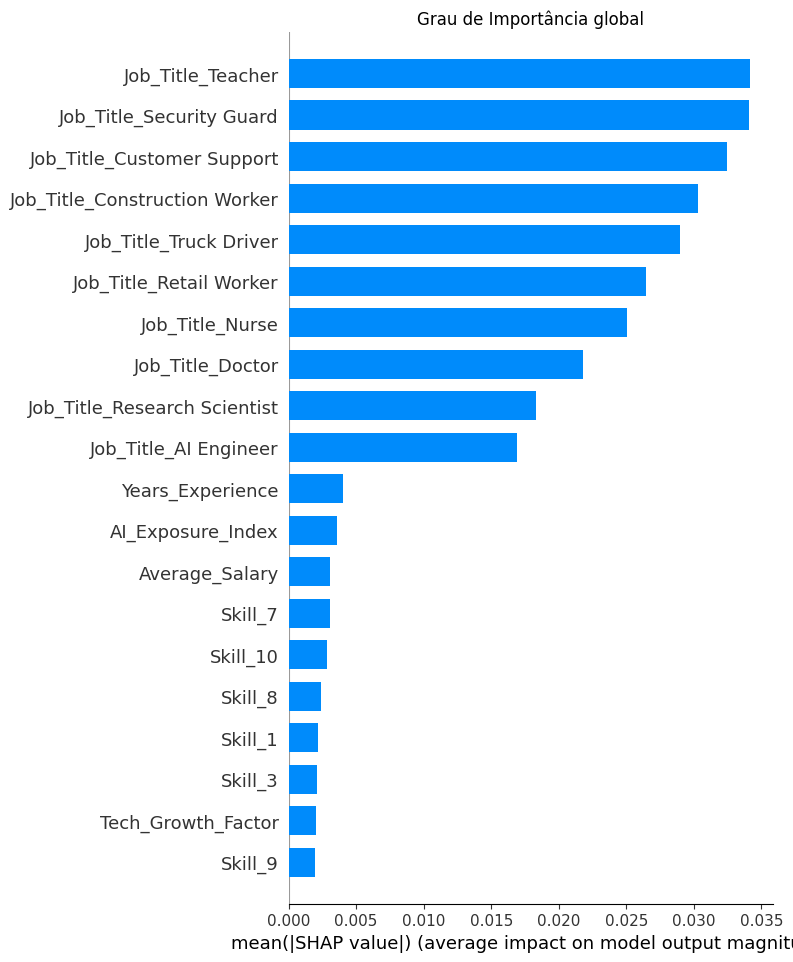

In [152]:
shap.summary_plot(shap_values, X_test_sample, plot_type="bar", show=False)
plt.title("Grau de Importância global")
plt.show()

Plotagem de Importância das Variáveis - Interpretação Global


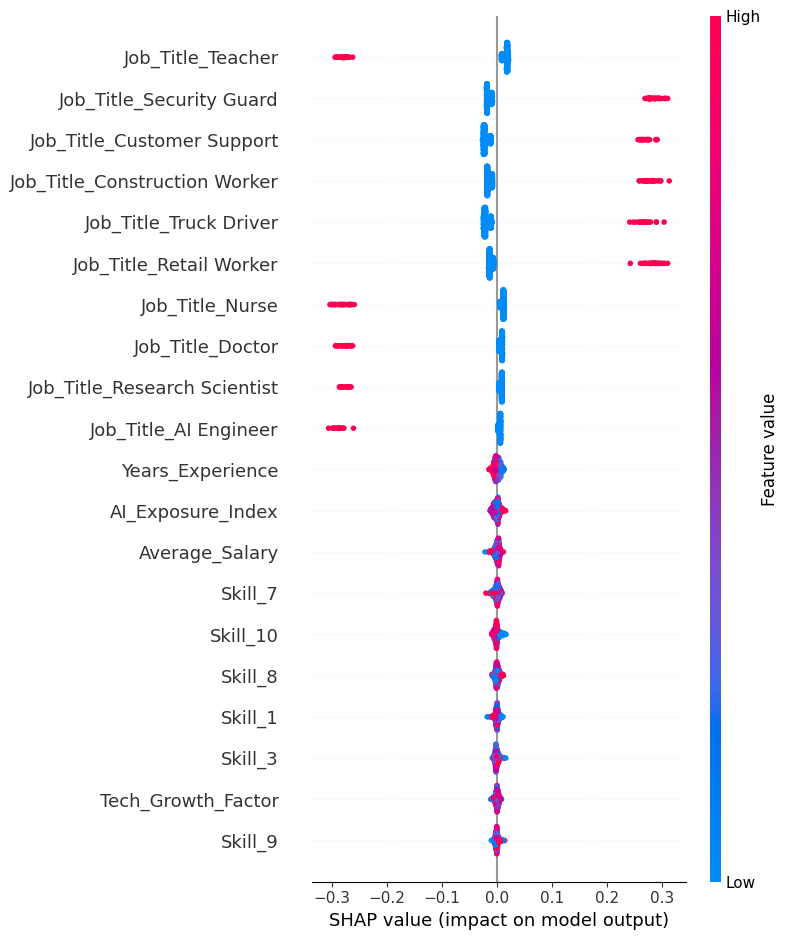

In [153]:
print("Plotagem de Importância das Variáveis - Interpretação Global")
figure = plt.figure()
shap.summary_plot(shap_values, X_test_sample)

In [154]:
from lime.lime_tabular import LimeTabularExplainer

feature_names = X_train.columns.tolist()


lime_explainer = LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=feature_names,
    class_names=['Automation_Probability'], # nome da variável alvo
    mode='regression'
)

print("LIME: explicador inicializado")

LIME: explicador inicializado


In [155]:
random_instance_idx = 0
instance_to_explain = X_test_sample.iloc[random_instance_idx].values

# Generate explanation for the instance
lime_explanation = lime_explainer.explain_instance(
    data_row=instance_to_explain,
    predict_fn=rf.predict,
    num_features=5
)

print(f"LIME: explicação geradada a partir das instâncias de modo randômico{random_instance_idx}.")
print("Top features para essa predição")
for feature, weight in lime_explanation.as_list():
    print(f"- {feature}: {weight:.4f}")

LIME: explicação geradada a partir das instâncias de modo randômico0.
Top features para essa predição
- Job_Title_Construction Worker <= 0.00: -0.2778
- Job_Title_Security Guard <= 0.00: -0.2769
- Job_Title_Truck Driver <= 0.00: -0.2768
- Job_Title_Retail Worker <= 0.00: -0.2754
- Job_Title_Teacher > 0.00: -0.2679


/Users/jwcunha/.pyenv/versions/3.12.9/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


In [156]:
# lime_explanation.show_in_notebook(show_table=True, show_all=False)
from IPython.display import display, HTML
display(HTML(lime_explanation.as_html(show_table=True, show_all=False)))
print("Explicação visual do LIME.")

Explicação visual do LIME.


#Questões

De acordo com a matrix de correlação, faça dois experimentos:


1.   Exclua dois tipos skills e analise o resultado do lime, bem como o predict
2.   Exclua o AI_Exposure_Index e o Years_Experience

após isso, discuta os resultados e avalie o melhor após da run nas células do LIME e SHAP



Correlação das skills com o alvo:
 Skill_1     0.031
Skill_2     0.024
Skill_3    -0.020
Skill_4     0.006
Skill_5    -0.026
Skill_6     0.012
Skill_7    -0.010
Skill_8    -0.016
Skill_9     0.001
Skill_10    0.003
Name: Automation_Probability_2030, dtype: float64
Skills removidas: ['Skill_1', 'Skill_5']
                                R2    RMSE     MAE
Baseline                    0.8494  0.0983  0.0819
Sem ['Skill_1', 'Skill_5']  0.8498  0.0982  0.0815

Predict instância 221: baseline=0.1460 | exp1=0.1488 | real=0.2300

LIME - Experimento 1:
- Job_Title_Security Guard <= 0.00: -0.2904
- Job_Title_Teacher > 0.00: -0.2720
- Job_Title_Retail Worker <= 0.00: -0.2711
- Job_Title_Truck Driver <= 0.00: -0.2707
- Job_Title_Research Scientist <= 0.00: 0.2536


Background dataset has 500 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=500 when initializing the masker.
 93%|=================== | 466/500 [00:12<00:00]       

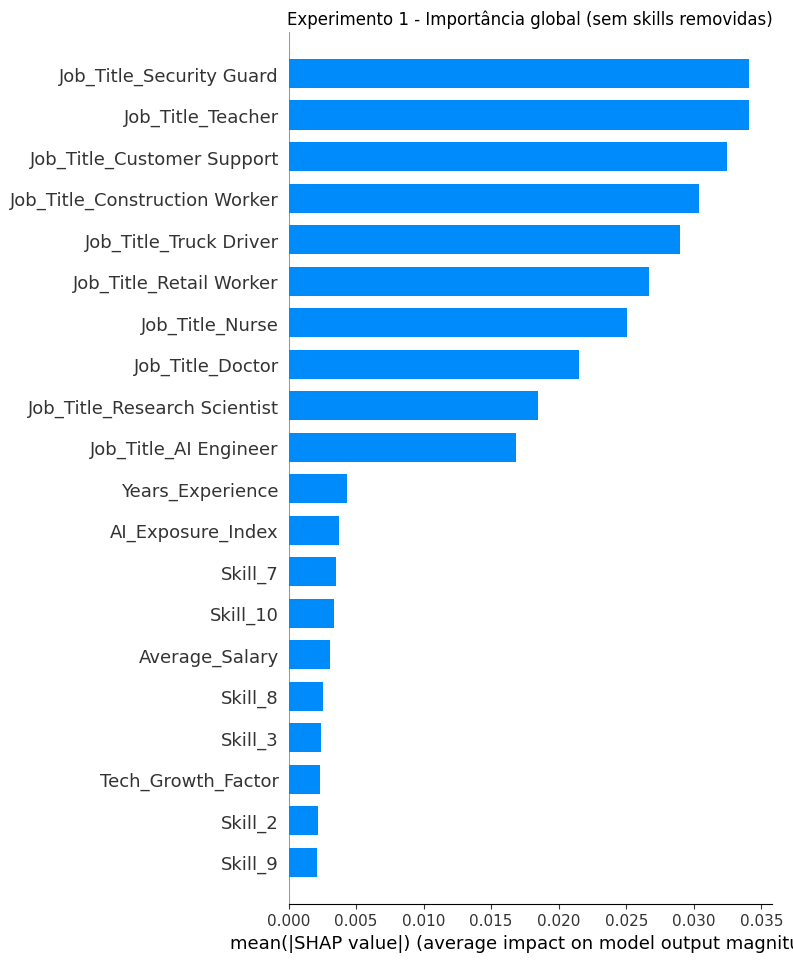

In [157]:
# Experimento 1: remover as duas skills mais correlacionadas com o alvo (|corr|)
corr_target = df.corr(numeric_only=True)['Automation_Probability_2030'].drop('Automation_Probability_2030')
skills_corr = corr_target[[c for c in corr_target.index if c.startswith('Skill_')]]
skills_drop = skills_corr.abs().sort_values(ascending=False).head(2).index.tolist()
print("Correlação das skills com o alvo:\n", skills_corr.round(3))
print("Skills removidas:", skills_drop)

X_train_e1 = X_train.drop(columns=skills_drop)
X_test_e1 = X_test.drop(columns=skills_drop)

rf_e1 = RandomForestRegressor(random_state=101)
rf_e1.fit(X_train_e1, y_train)
pred_e1 = rf_e1.predict(X_test_e1)

pred_base = rf.predict(X_test)
resultados = pd.DataFrame({
    'R2': [r2_score(y_test, pred_base), r2_score(y_test, pred_e1)],
    'RMSE': [mean_squared_error(y_test, pred_base) ** 0.5, mean_squared_error(y_test, pred_e1) ** 0.5],
    'MAE': [mean_absolute_error(y_test, pred_base), mean_absolute_error(y_test, pred_e1)],
}, index=['Baseline', f'Sem {skills_drop}'])
print(resultados.round(4))

# Mesma instância do LIME base, para comparação direta
idx_label = X_test_sample.index[random_instance_idx]
inst_e1 = X_test_e1.loc[idx_label]
print(f"\nPredict instância {idx_label}: baseline={rf.predict(X_test_sample.iloc[[random_instance_idx]])[0]:.4f} | "
      f"exp1={rf_e1.predict(inst_e1.to_frame().T)[0]:.4f} | real={y_test.loc[idx_label]:.4f}")

lime_e1 = LimeTabularExplainer(
    training_data=X_train_e1.values,
    feature_names=X_train_e1.columns.tolist(),
    class_names=['Automation_Probability'],
    mode='regression',
    random_state=42
)
exp_e1 = lime_e1.explain_instance(
    data_row=inst_e1.values,
    predict_fn=lambda a: rf_e1.predict(pd.DataFrame(a, columns=X_train_e1.columns)),
    num_features=5
)
print("\nLIME - Experimento 1:")
for f, w in exp_e1.as_list():
    print(f"- {f}: {w:.4f}")
display(HTML(exp_e1.as_html(show_table=True, show_all=False)))

# SHAP: importância global sem as skills removidas
expl_e1 = shap.TreeExplainer(rf_e1, X_train_e1.loc[X_train_sample.index])
sv_e1 = expl_e1.shap_values(X_test_e1.loc[X_test_sample.index])
shap.summary_plot(sv_e1, X_test_e1.loc[X_test_sample.index], plot_type="bar", show=False)
plt.title("Experimento 1 - Importância global (sem skills removidas)")
plt.show()


### Experimento 1 - Análise (remoção de Skill_1 e Skill_5)

**Critério:** as duas skills com maior |correlação| com `Automation_Probability_2030` na matriz de correlação (Skill_1 = +0.031, Skill_5 = -0.026). Mesmo as maiores são praticamente nulas.

**Predict:** R² 0.8494 → 0.8498, RMSE 0.0983 → 0.0982, MAE 0.0819 → 0.0815. Sem mudança material. Na instância 221 a predição foi de 0.146 para 0.149 (real = 0.23).

**LIME:** as explicações são dominadas por `Job_Title_*`, com pesos de ordem 0.25-0.29. Pequenas diferenças entre as execuções (ordem das features, aparição de `Job_Title_Research Scientist`) vêm da amostragem aleatória do LIME, não da remoção das skills. As skills não aparecem entre as 5 features mais importantes em nenhuma das duas versões.

**Conclusão:** as skills removidas não carregam sinal. O modelo prevê a probabilidade quase só pelo cargo, então remover as duas skills não degrada o modelo e simplifica a explicação.


Correlação com o alvo:
 AI_Exposure_Index    0.014
Years_Experience    -0.018
Name: Automation_Probability_2030, dtype: float64
                                                        R2    RMSE     MAE
Baseline                                            0.8494  0.0983  0.0819
Exp1 sem ['Skill_1', 'Skill_5']                     0.8498  0.0982  0.0815
Exp2 sem ['AI_Exposure_Index', 'Years_Experience']  0.8482  0.0987  0.0825

Predict instância 221: baseline=0.1460 | exp1=0.1488 | exp2=0.1454 | real=0.2300

LIME - Experimento 2:
- Job_Title_Security Guard <= 0.00: -0.2906
- Job_Title_Truck Driver <= 0.00: -0.2726
- Job_Title_Teacher > 0.00: -0.2712
- Job_Title_Retail Worker <= 0.00: -0.2670
- Job_Title_Research Scientist <= 0.00: 0.2530


Background dataset has 500 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=500 when initializing the masker.
 98%|===================| 492/500 [00:13<00:00]        

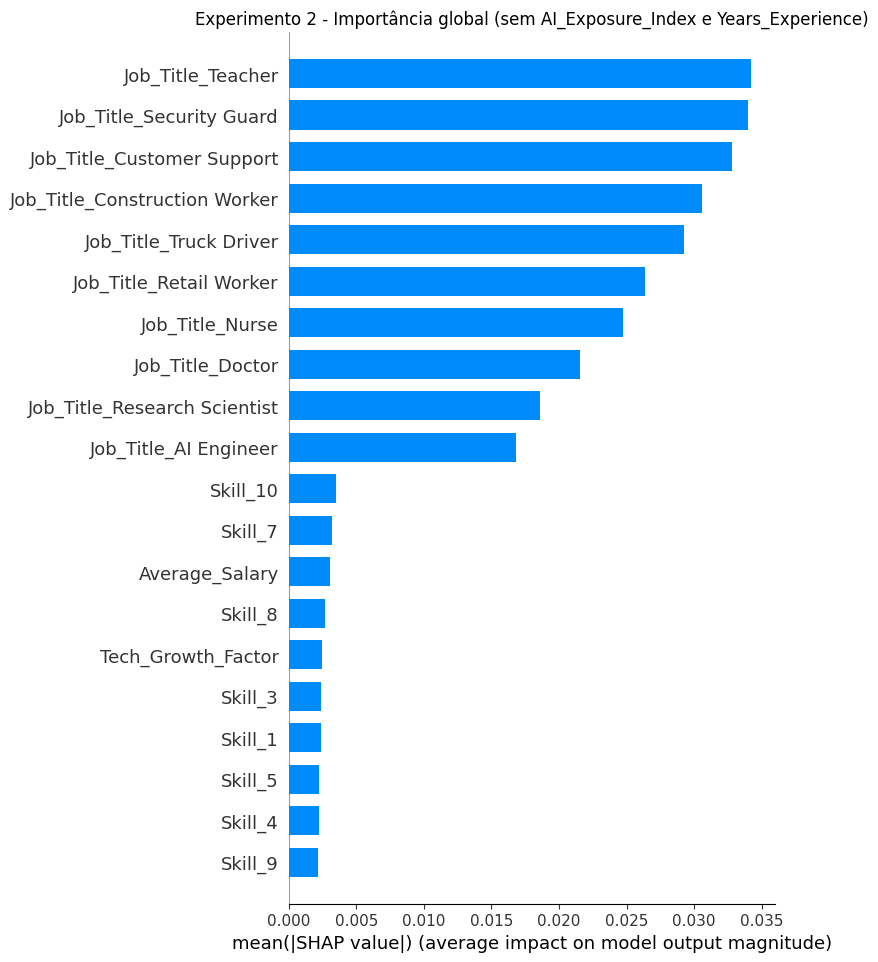

In [158]:
# Experimento 2: remover AI_Exposure_Index e Years_Experience
cols_drop = ['AI_Exposure_Index', 'Years_Experience']
print("Correlação com o alvo:\n", df[cols_drop + ['Automation_Probability_2030']].corr()['Automation_Probability_2030'].drop('Automation_Probability_2030').round(3))

X_train_e2 = X_train.drop(columns=cols_drop)
X_test_e2 = X_test.drop(columns=cols_drop)

rf_e2 = RandomForestRegressor(random_state=101)
rf_e2.fit(X_train_e2, y_train)
pred_e2 = rf_e2.predict(X_test_e2)

resultados2 = pd.DataFrame({
    'R2': [r2_score(y_test, pred_base), r2_score(y_test, pred_e1), r2_score(y_test, pred_e2)],
    'RMSE': [mean_squared_error(y_test, p) ** 0.5 for p in (pred_base, pred_e1, pred_e2)],
    'MAE': [mean_absolute_error(y_test, p) for p in (pred_base, pred_e1, pred_e2)],
}, index=['Baseline', f'Exp1 sem {skills_drop}', f'Exp2 sem {cols_drop}'])
print(resultados2.round(4))

# Mesma instância dos experimentos anteriores
inst_e2 = X_test_e2.loc[idx_label]
print(f"\nPredict instância {idx_label}: baseline={rf.predict(X_test_sample.iloc[[random_instance_idx]])[0]:.4f} | "
      f"exp1={rf_e1.predict(inst_e1.to_frame().T)[0]:.4f} | exp2={rf_e2.predict(inst_e2.to_frame().T)[0]:.4f} | real={y_test.loc[idx_label]:.4f}")

lime_e2 = LimeTabularExplainer(
    training_data=X_train_e2.values,
    feature_names=X_train_e2.columns.tolist(),
    class_names=['Automation_Probability'],
    mode='regression',
    random_state=42
)
exp_e2 = lime_e2.explain_instance(
    data_row=inst_e2.values,
    predict_fn=lambda a: rf_e2.predict(pd.DataFrame(a, columns=X_train_e2.columns)),
    num_features=5
)
print("\nLIME - Experimento 2:")
for f, w in exp_e2.as_list():
    print(f"- {f}: {w:.4f}")
display(HTML(exp_e2.as_html(show_table=True, show_all=False)))

# SHAP: importância global sem as features removidas
expl_e2 = shap.TreeExplainer(rf_e2, X_train_e2.loc[X_train_sample.index])
sv_e2 = expl_e2.shap_values(X_test_e2.loc[X_test_sample.index])
shap.summary_plot(sv_e2, X_test_e2.loc[X_test_sample.index], plot_type="bar", show=False)
plt.title("Experimento 2 - Importância global (sem AI_Exposure_Index e Years_Experience)")
plt.show()


### Experimento 2 - Análise (remoção de AI_Exposure_Index e Years_Experience)

**Predict:** R² 0.8494 (baseline) → 0.8482, RMSE 0.0983 → 0.0987, MAE 0.0819 → 0.0825. Queda mínima. Na instância 221 a predição foi de 0.146 para 0.145 (real = 0.23).

**LIME:** as cinco features principais continuam sendo `Job_Title_*` (pesos 0.25-0.29). Nenhuma das duas variáveis removidas aparecia no top 5 do baseline.

### Discussão e melhor modelo

| Modelo | R² | RMSE | MAE |
|---|---|---|---|
| Baseline | 0.8494 | 0.0983 | 0.0819 |
| Exp1 (sem Skill_1, Skill_5) | 0.8498 | 0.0982 | 0.0815 |
| Exp2 (sem AI_Exposure_Index, Years_Experience) | 0.8482 | 0.0987 | 0.0825 |

As três versões são equivalentes: as diferenças (~0.001 em R²) estão dentro da variação esperada entre execuções de Random Forest e de uma divisão treino/teste. Com os resultados, o **Exp1 tem o melhor desempenho numérico**, mas sem relevância prática. As duas remoções mostram que as features removidas não carregam sinal, e a probabilidade de automação é explicada quase só por `Job_Title`. Como o dataset parece sintético, não se deve inferir relações causais entre skills, experiência ou exposição à IA e o risco de automação.
